In [31]:
import numpy as np
from numpy.random import randn
from scipy.linalg import sqrtm, inv
import matplotlib.pyplot as plt

In [32]:
def epsilon_and_nu(P: float, Sigma: np.ndarray):
    nu = 1/ (2 * np.pi * np.sqrt(np.linalg.det(Sigma)))
    epsilon = (1-P) * nu

    return epsilon, nu

def in_error_ellipse(x: np.ndarray, mu: np.ndarray, Sigma: np.ndarray, P=0.95):
    epsilon, nu = epsilon_and_nu(P, Sigma)
    rhs = -2*np.log(epsilon / nu)   # = -2 log(1-P)
    lhs = (x - mu).T @ np.linalg.inv(Sigma) @ (x - mu)
    return lhs <= rhs
    
def plot_gaussian(mu, Sigma, N, show=True):
    x_arr = randn(N,2) @ sqrtm(Sigma) + mu

    x_in = np.array([x for x in x_arr if in_error_ellipse(x, mu, Sigma)])
    x_out = np.array([x for x in x_arr if not in_error_ellipse(x, mu, Sigma)])

    e, _ = epsilon_and_nu(0.95, Sigma)
    print(f"Percentage of points in ellipse {len(x_in) / N * 100}")
    plt.scatter(x_in[:,0], x_in[:,1], marker='.')
    plt.scatter(x_out[:,0], x_out[:,1], marker='.')
    plt.title("95% Confidence Error Ellipse")
    if show:
        plt.show()

def get_ellipse_points(mu: np.ndarray, Sigma: np.ndarray, P=0.95, N=200):
    t = np.linspace(0, 2*np.pi, N)
    circle = np.vstack((np.cos(t), np.sin(t)))
    rhs = -2*np.log(1-P)
    ellipse = np.sqrt(rhs) * circle
    scaled_ellipse = sqrtm(Sigma) @ ellipse # circle -> ellipse
    return scaled_ellipse + mu.reshape(2,1)

In [33]:
dt = 1
Q = np.zeros((4,4))
mu_w = np.array([0, 0, 0.3, 0.3]).T
mu_v = np.array([400, 400]).T
# Nothing for position noise
Q[2:4, 2:4] = np.eye(2)

R = 9*np.eye(2)

def u_input(t):
    return -2.5 * np.array([
        np.cos(0.05*t), np.sin(0.05*t)
    ])

In [34]:
A = np.zeros((4,4))
A[0:2, 0:2] = np.eye(2)
A[0:2, 2:4] = dt*np.eye(2)
A[2:4, 2:4] = np.eye(2)

B = np.zeros((4,2))
B[2:4, 0:2] = np.eye(2)

C = np.zeros((2,4))
C[0:2, 0:2] = np.eye(2)

x0 = np.array([1000, 0, 0, 50])

In [35]:
def noise_W(mu, Q, seed=None):
    if seed is not None:
        np.random.seed(seed)

    return np.random.multivariate_normal(
        mean=mu,
        cov=Q
    )

def noise_V(mu, R, seed=None):
    if seed is not None:
        np.random.seed(seed)

    return np.random.multivariate_normal(
        mean=mu,
        cov=R
    )

print(noise_W(mu_w, Q))
print(noise_V(mu_v, R))


[0.         0.         0.14064867 1.16444073]
[402.51880559 398.23364055]


In [36]:
N = 100 # Timesteps of 1 second

class Trajectory:
    def __init__(self, x, u, meas):
        self.x_arr = x
        self.u_arr = u
        self.meas_arr = meas

def one_trajectory(N, show=True, return_results = True):

    meas_arr = np.zeros((N,2))
    u_arr = np.zeros((N,2))
    x_arr = np.zeros((N,4))


    x_arr[0] = x0
    meas_arr[0] = C @ x0 + noise_V(mu_v, R)

    for t in range(N-1):
        u_arr[t] = u_input(t).T

        x_arr[t+1] = A @ x_arr[t] + B @ u_arr[t] + noise_W(mu_w, Q)
        meas_arr[t+1] = C @ x_arr[t+1] + noise_V(mu_v, R)

    
    
    if show:
        plt.plot(x_arr[:,0], x_arr[:,1], label="Trajectory", color="tab:orange", zorder=0)
        plt.scatter(meas_arr[:,0], meas_arr[:,1], label="Noisy GPS Measurements", s=4, color="tab:blue", zorder=1)
        plt.scatter([x0[0]], [x0[1]], color="tab:red", label="Starting Position", s=40, marker="o")
        plt.xlabel("X [m]")
        plt.ylabel("Y [m]")
        plt.title("Drone Position")
        plt.legend(("Trajectory", "Noisy GPS Measurements", "Starting Position"))
        plt.show()

    if return_results:
        return Trajectory(x_arr, u_arr, meas_arr)
        


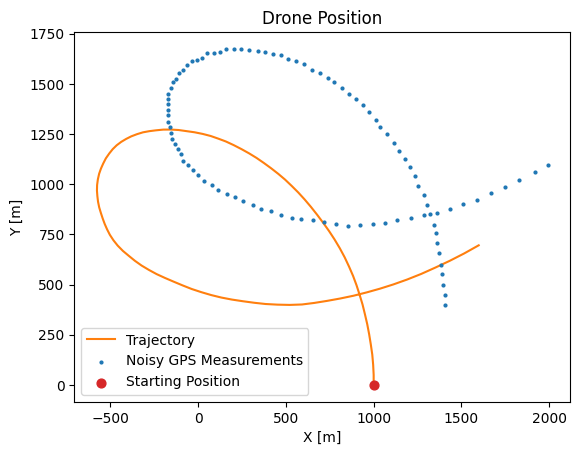

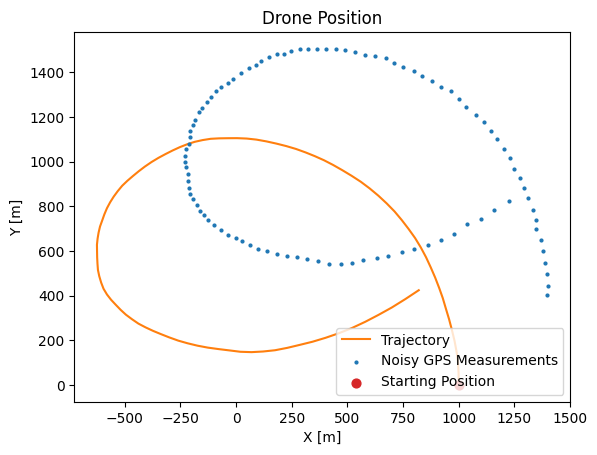

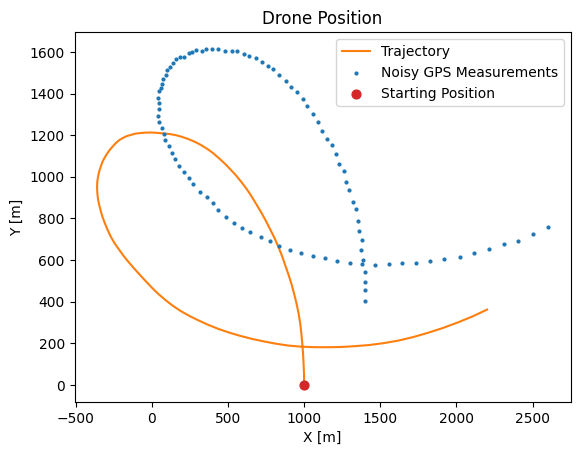

In [37]:


data_arrs: list[Trajectory] = []
data_arrs.append(one_trajectory(100, show=True))
data_arrs.append(one_trajectory(100, show=True))
data_arrs.append(one_trajectory(100, show=True))

In [38]:
mu0 = np.array([1500, 100, 0, 55])
Sigma0 = np.zeros((4,4))
Sigma0[0:2, 0:2] = 250000*np.eye(2)
Sigma0[2:4, 2:4] = np.eye(2)

In [39]:
mu_arr = np.zeros((N,4))
Sigma_arr = np.zeros((N,4,4))

mu_arr[0] = mu0
Sigma_arr[0] = Sigma0

x_arr = data_arrs[0].x_arr
u_arr = data_arrs[0].u_arr
meas_arr = data_arrs[0].meas_arr


for t in range(N-1):
    mu_predict = A @ mu_arr[t] + B @ u_arr[t] + mu_w
    Sigma_predict = A @ Sigma_arr[t] @ A.T + Q

    K = Sigma_predict @ C.T @ inv(C @ Sigma_predict @ C.T + R)

    mu_arr[t+1] = mu_predict + K @ (meas_arr[t] - (C @ mu_predict + mu_v))
    Sigma_arr[t+1] = Sigma_predict - K @ C @ Sigma_predict


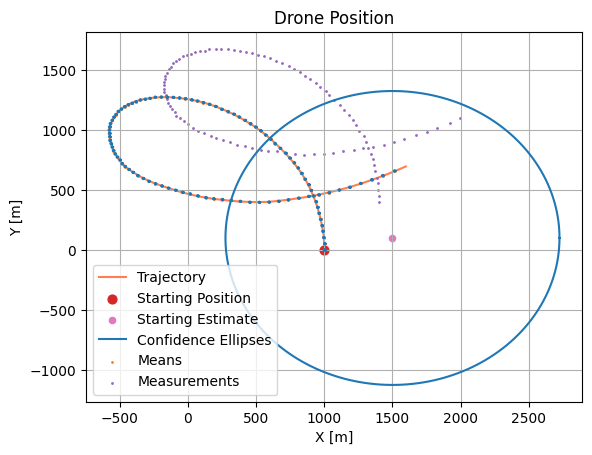

In [82]:


plt.plot(x_arr[:,0], x_arr[:,1], color="coral", zorder=1)
plt.scatter([x0[0]], [x0[1]], color="tab:red", label="Starting Position", s=40, marker="o")
plt.scatter([mu_arr[0,0]], [mu_arr[0,1]], color="tab:pink", s=20, marker="o")

for mu, sigma, meas in zip(mu_arr, Sigma_arr, meas_arr):
    mu = mu[0:2]
    sigma = sigma[0:2, 0:2]
    plt.plot(*get_ellipse_points(mu, sigma), color='tab:blue')
    plt.scatter(*mu[:2], color='tab:orange', s=1)
    plt.scatter(*meas[:2], color='tab:purple', s=1)
    # plt.scatter(*mu, color='tab:orange', s=1)
    # plt.scatter(*meas_arr, color='tab:green', s=1)

plt.xlabel("X [m]")
plt.ylabel("Y [m]")
plt.title("Drone Position")
plt.grid("minor")
plt.legend(("Trajectory", "Starting Position", "Starting Estimate", "Confidence Ellipses", "Means", "Measurements"))
plt.show()
# print([mu_arr[0]])

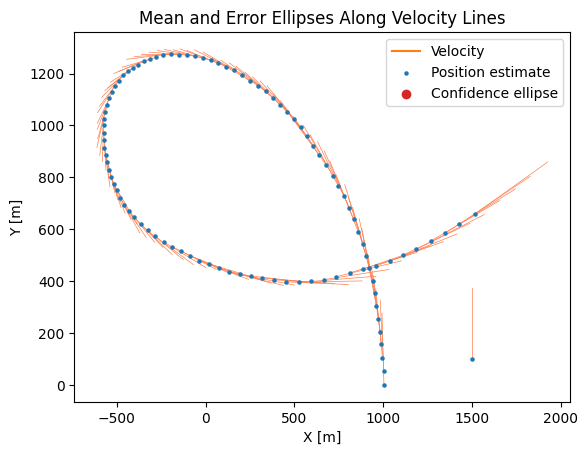

In [84]:
handles = []
vel_handle = plt.plot([], [], color="tab:orange", label="Velocity")[0] # just want one line
pos_handle = plt.scatter([], [], color="tab:blue", s=5, label="Position estimate")
ell_handle = plt.scatter([], [], color="tab:red", label="Confidence ellipse")

for mu, sigma in zip(mu_arr, Sigma_arr):
    position = mu[0:2]
    velocity = mu[2:4] * 5
    sigma = sigma[0:2, 0:2]
    handles.append(
        plt.plot([position[0], position[0] + velocity[0]], [position[1], position[1] + velocity[1]], 
                 color="coral", zorder=0, label="Velocity lines", linewidth=0.5)
    )
    handles.append(
        plt.scatter([position[0]], [position[1]], color="tab:blue", zorder=1, s=5, label="Position estimates")
    )
    
    # ellipse_x, ellipse_y = get_ellipse_points(position, sigma)
    # ellipse_x += velocity[0]
    # ellipse_y += velocity[1]
    # handles.append(
    #     plt.plot(ellipse_x, ellipse_y, color='tab:red', zorder=2, alpha=0.8, label="Confidence Ellipse")
    # )
    # plt.xlim(-1200, 1600)
    # plt.ylim(-500, -500+2800)

plt.legend(handles=[vel_handle, pos_handle, ell_handle])
plt.title("Mean and Error Ellipses Along Velocity Lines")
plt.xlabel("X [m]")
plt.ylabel("Y [m]")
plt.show()

In [ ]:
mu_arr.shape

(100, 4)